In [1]:
!pip install gymnasium pettingzoo matplotlib seaborn > /dev/null 2>&1

In [2]:
import numpy as np
import random
import matplotlib.pyplot as plt
import seaborn as sns
from gymnasium import spaces
from pettingzoo import ParallelEnv

In [3]:
def stochastic_reward(delta0, delta, delta1):
    # 1. Define the three base 3x3 matrices (P0 Action x P1 Action x [Low, High])
    base_m1 = np.array([
        [[10-delta0, 10+delta0], [0-delta, 0+delta],  [-1-delta, -1+delta]],
        [[1-delta, 1+delta],   [6-delta1, 6+delta1], [3-delta, 3+delta]],
        [[0-delta, 0+delta],   [2-delta, 2+delta],  [5-delta, 5+delta]]
    ])

    base_m2 = np.array([
        [[12-delta0, 12+delta0], [-2-delta, -2+delta],  [1-delta, 1+delta]],
        [[-4-delta, -4+delta],   [8-delta1, 8+delta1], [5-delta, 5+delta]],
        [[2-delta, 2+delta],   [-1-delta, -1+delta],  [6-delta, 6+delta]]
    ])

    base_m3 = np.array([
        [[15-delta0, 15+delta0], [-45-delta, -45+delta],  [2-delta, 2+delta]],
        [[-48-delta, -48+delta],   [5-delta1, 5+delta1], [4-delta, 4+delta]],
        [[1-delta, 1+delta],   [0-delta, 0+delta],  [4-delta, 4+delta]]
    ])

    payoff = np.array([base_m1, base_m2, base_m3])

    # Access: payoff_tensor[action_0, action_1, action_2] returns the shared [Low, High] range.
    return payoff

In [27]:
# other utilities
f = lambda low, high: np.random.uniform(low, high)

# parameters to setting for
delta0=2
delta=0.5
delta1=2

In [28]:
class MatrixGame(ParallelEnv):
    metadata = {'render_modes': ['human']}

    def __init__(self, delta0, delta, delta1):
        self.agents = ["player_0", "player_1", "player_2"] # we have three agent's for all algorithm
        self.possible_agents = self.agents[:] # this is the list of possible agent's
        # this is the settings for the matrix (what the user need to provide)
        self.delta0 = delta0
        self.delta = delta
        self.delta1 = delta1
        self.reward_matrix = stochastic_reward(self.delta0, self.delta, self.delta1)

        # this is a function that return a value some value

        actions = {
          "player_0": spaces.Discrete(3),
          "player_1": spaces.Discrete(3),
          "player_2": spaces.Discrete(3),
        }

    def reset(self, seed=None, options=None):
        self.agents = self.possible_agents[:]
        self.rewards = stochastic_reward(self.delta0, self.delta, self.delta1)

    def step(self, actions):

      action_0 = actions[self.agents[0]]
      action_1 = actions[self.agents[1]]
      action_2 = actions[self.agents[2]]


      # we are going to select the action for an agent and compute uniform
      # with the value found it inside the matrix
      reward_range = self.reward_matrix[action_0, action_1, action_2]


      team_reward = f(reward_range[0], reward_range[1])
      return team_reward

In [29]:
class Qlearner:
    def __init__(self, action_size, alpha=0.1, epsilon = 1.0, learning_rate = 0.0,
        epsilon_min=0.01,
        epsilon_decay=0.99):
        self.action_size = action_size
        self.learning_rate = learning_rate
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay

        self.qtable = np.zeros(action_size)

        # --- Standard Q-learner parameters (copied) ---
        if learning_rate == 0.0:
            self.dynamic_lr = True
            # Action counter must now track joint actions: (State x Agent Action x Opponent Action)
            self.action_counter = np.zeros((self.action_size))
        else:
            self.dynamic_lr = False
            self.learning_rate = learning_rate

    def select_greedy(self):
        optimal_actions = np.flatnonzero(np.isclose(self.qtable, self.qtable.max()))
        return np.random.choice(optimal_actions)

    def update_epsilon(self):
        self.epsilon *= self.epsilon_decay
        self.epsilon = max(self.epsilon_min, self.epsilon)

    def select_action(self):
        if np.random.rand() < self.epsilon:
            # Explore: Choose a random action
            action = random.randrange(self.action_size)
        else:
            # Exploit: Choose the best action (handling ties)
            action = self.select_greedy()

        return action

    def update(self, action, reward):

        if not self.dynamic_lr:
            lr = self.learning_rate
        else:
            # The action counter must now use the JOINT action
            self.action_counter[action] += 1
            lr = 1.0 / self.action_counter[action]

        old_value = self.qtable[action]
        self.qtable[action] += lr * (reward - old_value) # this is the value that we are going to calculate, so Q(s, a) <- alpha * [r - Q(s^-1, a)]
        self.update_epsilon()

  # this completely work


In [30]:
num_trials = 40
num_episodes = 6000

joint_action_counts = np.zeros((5, 3, 3, 3))
# We only count for the last 10% of episodes as required
last_10_percent_start_episode = int(num_episodes * 0.9)
# -----------------------------------------------

# --- AGENT TYPE MAPPING (for clarity) ---
IL_TYPE, JAL_G_TYPE, JAL_B_TYPE, JAL_OB_TYPE, JAL_WOB_TYPE = 0, 1, 2, 3, 4

In [31]:


all_rewards_il = np.zeros((num_trials, num_episodes))

for trial in range(num_trials):
    # Initialize environment
    env = MatrixGame(delta0=delta0, delta=delta, delta1=delta1) #

    # Initialize agents in a dictionary
    agents = {
        "player_0": Qlearner(action_size=3,),
        "player_1": Qlearner(action_size=3,),
        "player_2": Qlearner(action_size=3,)
    }

    for episode in range(num_episodes):
        env.reset()
        # Agents select actions
        actions = {agent_name: agent_obj.select_action() for agent_name, agent_obj in agents.items()}

        # Environment step
        rewards = env.step(actions)

        all_rewards_il[trial, episode] = rewards

        if episode >= last_10_percent_start_episode:
          joint_action_counts[IL_TYPE, actions["player_0"], actions["player_1"], actions["player_2"]] += 1


        for agent_name, agent_obj in agents.items():
          # 1. Update Q-table (Ensure Qlearner.update is fixed to use TD error)
          agent_obj.update(actions[agent_name], rewards) # we have the same reward for each agent




In [32]:
class JointActionLearner:

    def __init__(
        self,
        agent_action_size,
        opponent_action_size, # <-- NEW: JAL needs to know the opponent's action space size
        learning_rate=0.0, # is alpha
        epsilon=1.0,
        epsilon_min=0.01,
        epsilon_decay=0.995,
        algorithm = 1
        # 1 : epsilon greedy
        # 2 : boltzmann
        # 3 : optimistic boltzmann
        # 4 : wob (weighted optimistic..)
    ):
        # we have also self.dynamic_lr
        self.action_size = agent_action_size
        self.opponent_action_size = opponent_action_size # Store opponent action size
        self.algorithm = algorithm

        # JAL Q-table: (State x Agent Action x Opponent Action x Opponent Action)
        # Note: Since state_size=1, this is effectively (Agent Action x Opponent Action x Opponent Action)
        self.qtable = np.zeros((self.action_size, self.opponent_action_size, self.opponent_action_size))

        # Belief about the opponent's action distribution P(a_{-i})
        # This is essentially a counter for each opponent action.
        self.opponent_action_counts = np.zeros((self.opponent_action_size, self.opponent_action_size)) # we have two agent againts


        # --- Standard Q-learner parameters (copied) ---\n",
        if learning_rate == 0.0:
            self.dynamic_lr = True
            # Action counter must now track joint actions: (State x Agent Action x Opponent Action)
            self.action_counter = np.zeros((self.action_size, self.opponent_action_size,self.opponent_action_size))
        else:
            self.dynamic_lr = False
            self.learning_rate = learning_rate


        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay

        # Temperature parameters for Boltzmann
        self.tau = 10000 # Start with a reasonable temperature
        self.tau_min = 0.01
        self.tau_decay = 0.995 # Slow decay

    def reset_agent(self):
        # Reset Q-table and opponent action counts
        self.qtable = np.zeros((self.action_size, self.opponent_action_size, self.opponent_action_size))
        self.opponent_action_counts = np.zeros((self.opponent_action_size, self.opponent_action_size))
        if self.dynamic_lr:
          self.action_counter = np.zeros((self.action_size, self.opponent_action_size, self.opponent_action_size))


    def get_opponent_policy(self):
        """
        Calculates the opponent's joint action probability distribution P(a_{-i}).
        This is the empirical frequency of observed opponent actions.
        """
        total_counts = np.sum(self.opponent_action_counts)
        if total_counts == 0:
            # Uniform joint distribution over both opponents' actions
            return np.ones((self.opponent_action_size, self.opponent_action_size)) / (self.opponent_action_size ** 2)

        # Return the normalized counts (probability distribution)
        return self.opponent_action_counts / total_counts

    def calculate_expected_utility(self):

      opponent_policy = self.get_opponent_policy()  # Shape: (A1, A2)

      # Q-values are the full 3D table: (A_i, A1, A2)
      q_values = self.qtable[:, :, :]

      expected_utilities = np.zeros(self.action_size)

      # Loop through each of the agent's possible actions (a_i)
      for a_i in range(self.action_size):

        # 1. Get the 2D slice of the Q-table for action a_i
        # Shape: (A1, A2)
        Q_slice = q_values[a_i, :, :]

        # 2. Perform Element-wise Multiplication (Hadamard product)
        # Resulting shape: (A1, A2)
        element_wise_product = Q_slice * opponent_policy

        # 3. Sum over all opponent actions (A1 and A2)
        # This gives the scalar Expected Utility for action a_i
        expected_utilities[a_i] = np.sum(element_wise_product)

      return expected_utilities

    def select_greedy(self):
        # Selects the action with the highest Expected Utility.
        expected_utilities = self.calculate_expected_utility()
        # Find all actions that are close to the maximum value (to break ties)
        optimal_actions = np.flatnonzero(np.isclose(expected_utilities, expected_utilities.max()))
        # Randomly choose one from the set of optimal actions
        return np.random.choice(optimal_actions)

    def select_action(self):
        if self.algorithm == 1:
            return self.greedy_algorithm()
        elif self.algorithm  == 2:
            return self.boltzmann_simple_algorithm()
        elif self.algorithm == 3:
            return self.optimistic_boltzmann()
        else: # self.algorithm == 4
            return self.weighted_optimistic_boltzmann()

    def calculate_max_q(self):
        """
        Implements the MaxQ(a_i) heuristic: max_{a_{-i}} Q(a_i, a_{-i}).
        This finds the maximum possible reward for each of the agent's actions,
        assuming the opponents will coordinate to give this agent the best reward.
        """
        # np.max(..., axis=(1, 2)) finds the max value across the two opponent dimensions,
        # resulting in a 1D array (size self.action_size).
        max_q_values = np.max(self.qtable, axis=(1, 2))
        return max_q_values

    def optimistic_boltzmann(self):
        """
        (Algorithm 3)
        Performs Boltzmann selection on the MaxQ(a_i) values.
        """

        # 1. Get the MaxQ values for each of our actions
        action_values = self.calculate_max_q()

        # 2. Perform Boltzmann (softmax) selection on these values
        max_val = np.max(action_values) # Subtract max for numerical stability
        exponent = (action_values - max_val) / self.tau # <-- ***FIXED*** (was using 'eu' before)

        exp_values = np.exp(exponent)
        probs = exp_values / np.sum(exp_values)

        # Choose action based on the calculated probabilities
        action = np.random.choice(len(action_values), p=probs)
        return action

    def boltzmann_simple_algorithm(self):
        """
        (Algorithm 2)
        Performs standard Boltzmann selection on the Expected Utility (EU) values.
        """

        # 1. Get the EU values for each of our actions
        action_values = self.calculate_expected_utility()

        # 2. Perform Boltzmann (softmax) selection
        max_val = np.max(action_values) # Subtract max for numerical stability
        exponent = (action_values - max_val) / self.tau

        exp_values = np.exp(exponent)
        probs = exp_values / np.sum(exp_values)

        # Choose action based on the calculated probabilities
        action = np.random.choice(len(probs), p=probs)
        return action

    def get_maxq_match_probability(self):
        """
        Calculates the probability P(a_{-i}* | a_i) that the opponents play the
        joint action a_{-i}* that maximizes Q(a_i, a_{-i}) for a given a_i.
        """
        opponent_policy = self.get_opponent_policy() # Shape (OppA1, OppA2)
        match_probs = np.zeros(self.action_size)

        for a_i in range(self.action_size):
            # Q-values for agent action a_i across all opponent joint actions
            Q_slice = self.qtable[a_i, :, :] # Shape (OppA1, OppA2)

            # Find the joint opponent action (index) that yields the max Q-value
            # np.argmax flattens the 2D array, so we convert the flat index back to 2D
            flat_index = np.argmax(Q_slice)

            # Use np.unravel_index to convert the flat index back to (a1, a2) indices
            a1_star, a2_star = np.unravel_index(flat_index, Q_slice.shape)

            # Look up the probability of that optimal joint action in the belief
            match_probs[a_i] = opponent_policy[a1_star, a2_star]

        return match_probs

    def weighted_optimistic_boltzmann(self):
        """
        (Algorithm 4)
        Performs Boltzmann selection on the weighted factor:
        Factor(a_i) = MaxQ(a_i) * P(a_{-i}* | a_i)
        """

        # 1. Get MaxQ values, Shape: (MyA)
        max_q_values = self.calculate_max_q()

        # 2. Get match probabilities, Shape: (MyA)
        match_probs = self.get_maxq_match_probability()

        # 3. Calculate the weighted utility factor
        weighted_factor = max_q_values * match_probs

        # 4. Apply the Boltzmann (Softmax) function to the weighted factor
        max_val = np.max(weighted_factor) # For numerical stability

        exponent = (weighted_factor - max_val) / self.tau
        exp_values = np.exp(exponent) # <-- ***FIXED*** (Removed extra / self.tau)

        probs = exp_values / np.sum(exp_values)

        action = np.random.choice(self.action_size, p=probs)
        return action


    def greedy_algorithm(self):
        """
        (Algorithm 1)
        Standard epsilon-greedy policy, but uses select_greedy (based on EU) for exploitation.
        """
        if np.random.rand() < self.epsilon:
            action = random.randrange(self.action_size)
        else:
            action = self.select_greedy()
        return action

    def update_opponent_distribution(self, opponent_action1, opponent_action2):
        """
        Update the empirical belief about the opponent's joint policy.
        """
        self.opponent_action_counts[opponent_action1, opponent_action2] += 1

    def update_epsilon(self):
        self.epsilon *= self.epsilon_decay
        self.epsilon = max(self.epsilon_min, self.epsilon)

    def update_temperature(self):
        self.tau *= self.tau_decay
        self.tau = max(self.tau_min, self.tau)

    def update(self, action, opponent_action1, opponent_action2, reward):

        if not self.dynamic_lr:
            lr = self.learning_rate
        else:
            # The action counter must now use the JOINT action
            self.action_counter[action, opponent_action1, opponent_action2] += 1
            lr = 1.0 / self.action_counter[action, opponent_action1, opponent_action2]
        old_q_value = self.qtable[action, opponent_action1, opponent_action2]
        self.qtable[action, opponent_action1, opponent_action2] += lr * (reward - old_q_value)

        # --- Update Epsilon or Tau ---
        if self.algorithm == 1:
          self.update_epsilon()
        else:
          # Algorithms 2, 3, and 4 all use temperature
          self.update_temperature()

In [33]:

rewards_greedy_m = np.zeros((num_trials, num_episodes))
rewards_boltz_m = np.zeros((num_trials, num_episodes))
rewards_ob_m = np.zeros((num_trials, num_episodes))
rewards_wob_m = np.zeros((num_trials, num_episodes))

history_jal_greedy = []
history_jal_boltz = []
history_jal_ob = []
history_jal_wob = []


for trial in range(num_trials):
    # Initialize environment
    env = MatrixGame(delta0=delta0, delta=delta, delta1=delta1)


   ################################################################################################
   # JAL WITH EPSILON GREEDY SELECTION
    agent_0_jal_greedy = JointActionLearner(agent_action_size=3, opponent_action_size=3, algorithm = 1,)
    agent_1_jal_greedy = JointActionLearner(agent_action_size=3, opponent_action_size=3,algorithm = 1,)
    agent_2_jal_greedy = JointActionLearner(agent_action_size=3,opponent_action_size=3,algorithm = 1,)
   ################################################################################################
   # JAL WITH SIMPLE BOLTZMANN
    agent_0_jal_boltz = JointActionLearner(agent_action_size=3, opponent_action_size=3, algorithm = 2,)
    agent_1_jal_boltz = JointActionLearner(agent_action_size=3, opponent_action_size=3,algorithm = 2,)
    agent_2_jal_boltz = JointActionLearner(agent_action_size=3,opponent_action_size=3,algorithm = 2,)
   ################################################################################################
   # JAL WITH OPTIMISTIC BOLTZMAN
    agent_0_jal_ob = JointActionLearner(agent_action_size=3, opponent_action_size=3, algorithm = 3,)
    agent_1_jal_ob = JointActionLearner(agent_action_size=3, opponent_action_size=3,algorithm = 3,)
    agent_2_jal_ob = JointActionLearner(agent_action_size=3,opponent_action_size=3,algorithm = 3,)
   ################################################################################################
   # JAL WITH WOB (WEIGHTED OPTIMISTIC BOLTZMANN)
    agent_0_jal_wob = JointActionLearner(agent_action_size=3, opponent_action_size=3, algorithm = 4,)
    agent_1_jal_wob = JointActionLearner(agent_action_size=3, opponent_action_size=3,algorithm = 4,)
    agent_2_jal_wob = JointActionLearner(agent_action_size=3,opponent_action_size=3,algorithm = 4,)
   ################################################################################################

    # Run episodes
    for episode in range(num_episodes):
        env.reset()

        ################################################################################################
        a0_greedy = agent_0_jal_greedy.select_action()
        a1_greedy = agent_1_jal_greedy.select_action()
        a2_greedy = agent_2_jal_greedy.select_action()
        actions_greedy = {"player_0": a0_greedy, "player_1": a1_greedy, "player_2": a2_greedy}
        ################################################################################################
        a0_boltz = agent_0_jal_boltz.select_action()
        a1_boltz = agent_1_jal_boltz.select_action()
        a2_boltz = agent_2_jal_boltz.select_action()
        actions_boltz = {"player_0": a0_boltz, "player_1": a1_boltz, "player_2": a2_boltz}
        ################################################################################################
        a0_ob = agent_0_jal_ob.select_action()
        a1_ob = agent_1_jal_ob.select_action()
        a2_ob = agent_2_jal_ob.select_action()
        actions_ob = {"player_0": a0_ob, "player_1": a1_ob, "player_2": a2_ob}
        ################################################################################################
        a0_wob = agent_0_jal_wob.select_action()
        a1_wob = agent_1_jal_wob.select_action()
        a2_wob = agent_2_jal_wob.select_action()
        actions_wob = {"player_0": a0_wob, "player_1": a1_wob, "player_2": a2_wob}
        ################################################################################################



        # ENVIRONMENT STEP
        rewards_greedy = env.step(actions_greedy)
        rewards_boltz = env.step(actions_boltz)
        rewards_ob = env.step(actions_ob)
        rewards_wob = env.step(actions_wob)

        if episode >= last_10_percent_start_episode:
            joint_action_counts[JAL_G_TYPE, a0_greedy, a1_greedy, a2_greedy] += 1
            joint_action_counts[JAL_B_TYPE, a0_boltz, a1_boltz, a2_boltz] += 1
            joint_action_counts[JAL_OB_TYPE, a0_ob, a1_ob, a2_ob] += 1
            joint_action_counts[JAL_WOB_TYPE, a0_wob, a1_wob, a2_wob] += 1


        # WE NEED TO UPDAT THE AGENT PER ALGORITHM

        ################################################################################################
        agent_0_jal_greedy.update(a0_greedy, a1_greedy, a2_greedy, rewards_greedy)
        agent_1_jal_greedy.update(a1_greedy, a0_greedy, a2_greedy, rewards_greedy)
        agent_2_jal_greedy.update(a2_greedy, a0_greedy, a1_greedy, rewards_greedy)

        rewards_greedy_m[trial, episode] = rewards_greedy
        ################################################################################################

        ################################################################################################
        agent_0_jal_boltz.update(a0_boltz, a1_boltz, a2_boltz, rewards_boltz)
        agent_1_jal_boltz.update(a1_boltz, a0_boltz, a2_boltz, rewards_boltz)
        agent_2_jal_boltz.update(a2_boltz, a0_boltz, a1_boltz, rewards_boltz)

        rewards_boltz_m[trial, episode] = rewards_boltz
        rewards_boltz_m[trial, episode] = rewards_boltz
        rewards_boltz_m[trial, episode] = rewards_boltz
        ################################################################################################
        agent_0_jal_ob.update(a0_ob, a1_ob, a2_ob, rewards_ob)
        agent_1_jal_ob.update(a1_ob, a0_ob, a2_ob, rewards_ob)
        agent_2_jal_ob.update(a2_ob, a0_ob, a1_ob, rewards_ob)

        rewards_ob_m[trial, episode] = rewards_ob
        rewards_ob_m[trial, episode] = rewards_ob
        rewards_ob_m[trial, episode] = rewards_ob
        ################################################################################################
        agent_0_jal_wob.update(a0_wob, a1_wob, a2_wob, rewards_wob)
        agent_1_jal_wob.update(a1_wob, a0_wob, a2_wob, rewards_wob)
        agent_2_jal_wob.update(a2_wob, a0_wob, a1_wob, rewards_wob)

        rewards_wob_m[trial, episode] = rewards_wob
        rewards_wob_m[trial, episode] = rewards_wob
        rewards_wob_m[trial, episode] = rewards_wob
        ################################################################################################

        # NOW WE ARE GOING TO UPDATE THE OPPONENT DISTRIBUTION

        ################################################################################################
        agent_0_jal_greedy.update_opponent_distribution(a1_greedy, a2_greedy)
        agent_1_jal_greedy.update_opponent_distribution(a0_greedy, a2_greedy)
        agent_2_jal_greedy.update_opponent_distribution(a0_greedy, a1_greedy)
        ################################################################################################

        ################################################################################################
        agent_0_jal_boltz.update_opponent_distribution(a1_boltz, a2_boltz)
        agent_1_jal_boltz.update_opponent_distribution(a0_boltz, a2_boltz)
        agent_2_jal_boltz.update_opponent_distribution(a0_boltz, a1_boltz)
        ################################################################################################

        ################################################################################################
        agent_0_jal_ob.update_opponent_distribution(a1_ob, a2_ob)
        agent_1_jal_ob.update_opponent_distribution(a0_ob, a2_ob)
        agent_2_jal_ob.update_opponent_distribution(a0_ob, a1_ob)
        ################################################################################################

        ################################################################################################
        agent_0_jal_wob.update_opponent_distribution(a1_wob, a2_wob)
        agent_1_jal_wob.update_opponent_distribution(a0_wob, a2_wob)
        agent_2_jal_wob.update_opponent_distribution(a0_wob, a1_wob)
        ################################################################################################


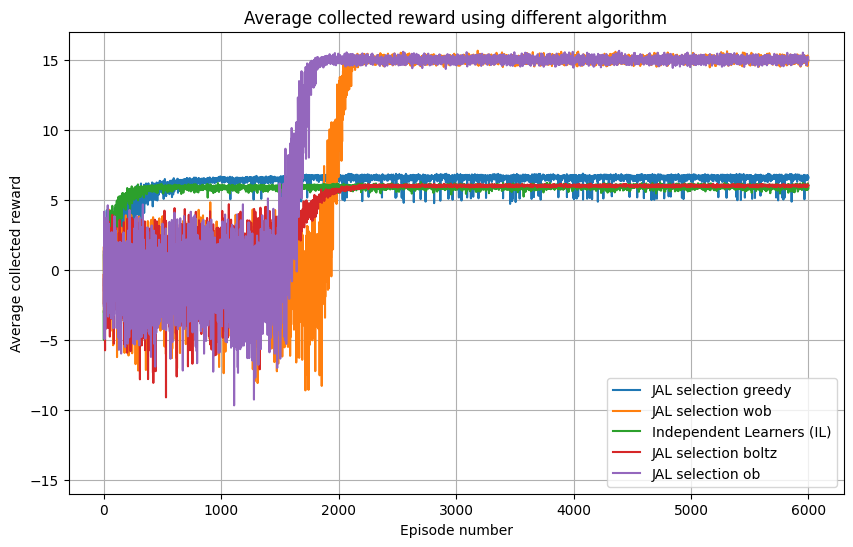

In [34]:

mean_rewards_per_episode_jal_greedy = np.mean(rewards_greedy_m, axis=0)
mean_rewards_per_episode_jal_boltz = np.mean(rewards_boltz_m, axis=0)
mean_rewards_per_episode_jal_ob = np.mean(rewards_ob_m, axis=0)
mean_rewards_per_episode_jal_wob = np.mean(rewards_wob_m, axis=0)
mean_rewards_per_episode_il = np.mean(all_rewards_il, axis=0)
mean_rewards_per_episode_il = np.mean(all_rewards_il, axis=0)



episodes = np.arange(num_episodes)

plt.figure(figsize=(10, 6))

plt.plot(episodes, mean_rewards_per_episode_jal_greedy, label='JAL selection greedy')
plt.plot(episodes, mean_rewards_per_episode_jal_wob, label='JAL selection wob')
plt.plot(episodes, mean_rewards_per_episode_il, label='Independent Learners (IL)')
plt.plot(episodes, mean_rewards_per_episode_jal_boltz, label='JAL selection boltz')
plt.plot(episodes, mean_rewards_per_episode_jal_ob, label='JAL selection ob')


plt.xlabel("Episode number")
plt.ylabel("Average collected reward")
plt.title("Average collected reward using different algorithm")
plt.legend()
plt.grid(True)
plt.ylim(-16, 17)
plt.show()

In [35]:
def plot_joint_action_heatmap(action_counts, agent_names, case_name):
    """
    Plots the empirical joint action distribution P(a1, a2, a3) for the last 10% of episodes.
    The sum of all 9 cells for a single agent type (across its 3 heatmaps) will sum to 1.
    """
    num_agent_types = len(agent_names)
    action_labels = ['a1', 'a2', 'a3'] # P1
    row_labels = ['b1', 'b2', 'b3'] # P2
    col_labels = ['c1', 'c2', 'c3'] # P3

    # Calculate the total counts PER AGENT TYPE (sum over a1, a2, a3)
    total_counts_per_agent = np.sum(action_counts, axis=(1, 2, 3), keepdims=True)

    # Divide to get the joint probability distribution P(a1, a2, a3) for each agent
    with np.errstate(divide='ignore', invalid='ignore'):
        distributions = np.nan_to_num(action_counts / total_counts_per_agent)

    # Find the single highest probability value across ALL plots for a consistent color scale
    global_vmax = np.max(distributions)
    if global_vmax == 0:
        global_vmax = 1.0

    fig, axes = plt.subplots(num_agent_types, 3, figsize=(15, 22), sharex=True, sharey=True)

    fig.suptitle(f"Empirical Joint Action Distribution (Last 10% Episodes) - {case_name}", fontsize=20, y=1.02)

    for i, name in enumerate(agent_names):
        distribution_cube = distributions[i]

        for a1_action in range(3):
            ax = axes[i, a1_action]

            # This is the joint probability P(a1_action, a2, a3)
            # The sum of all 9 cells across the 3 heatmaps will sum to 1.
            plot_data = distribution_cube[a1_action, :, :]

            sns.heatmap(plot_data, annot=True, fmt=".3f", cmap="viridis",
                        cbar=False, ax=ax, vmin=0, vmax=global_vmax) # Use global_vmax

            ax.set_xticklabels(col_labels)
            ax.set_yticklabels(row_labels)

            if i == 0:
                ax.set_title(f"P(a1='{action_labels[a1_action]}', a2, a3)", fontsize=14)
            if a1_action == 0:
                ax.set_ylabel(name, fontsize=14, fontweight='bold')
            if i == num_agent_types - 1:
                ax.set_xlabel("Player 3 Action", fontsize=12)
            if a1_action != 0:
                ax.set_yticklabels([])

    plt.tight_layout(rect=[0, 0, 1, 1])
    plt.show()


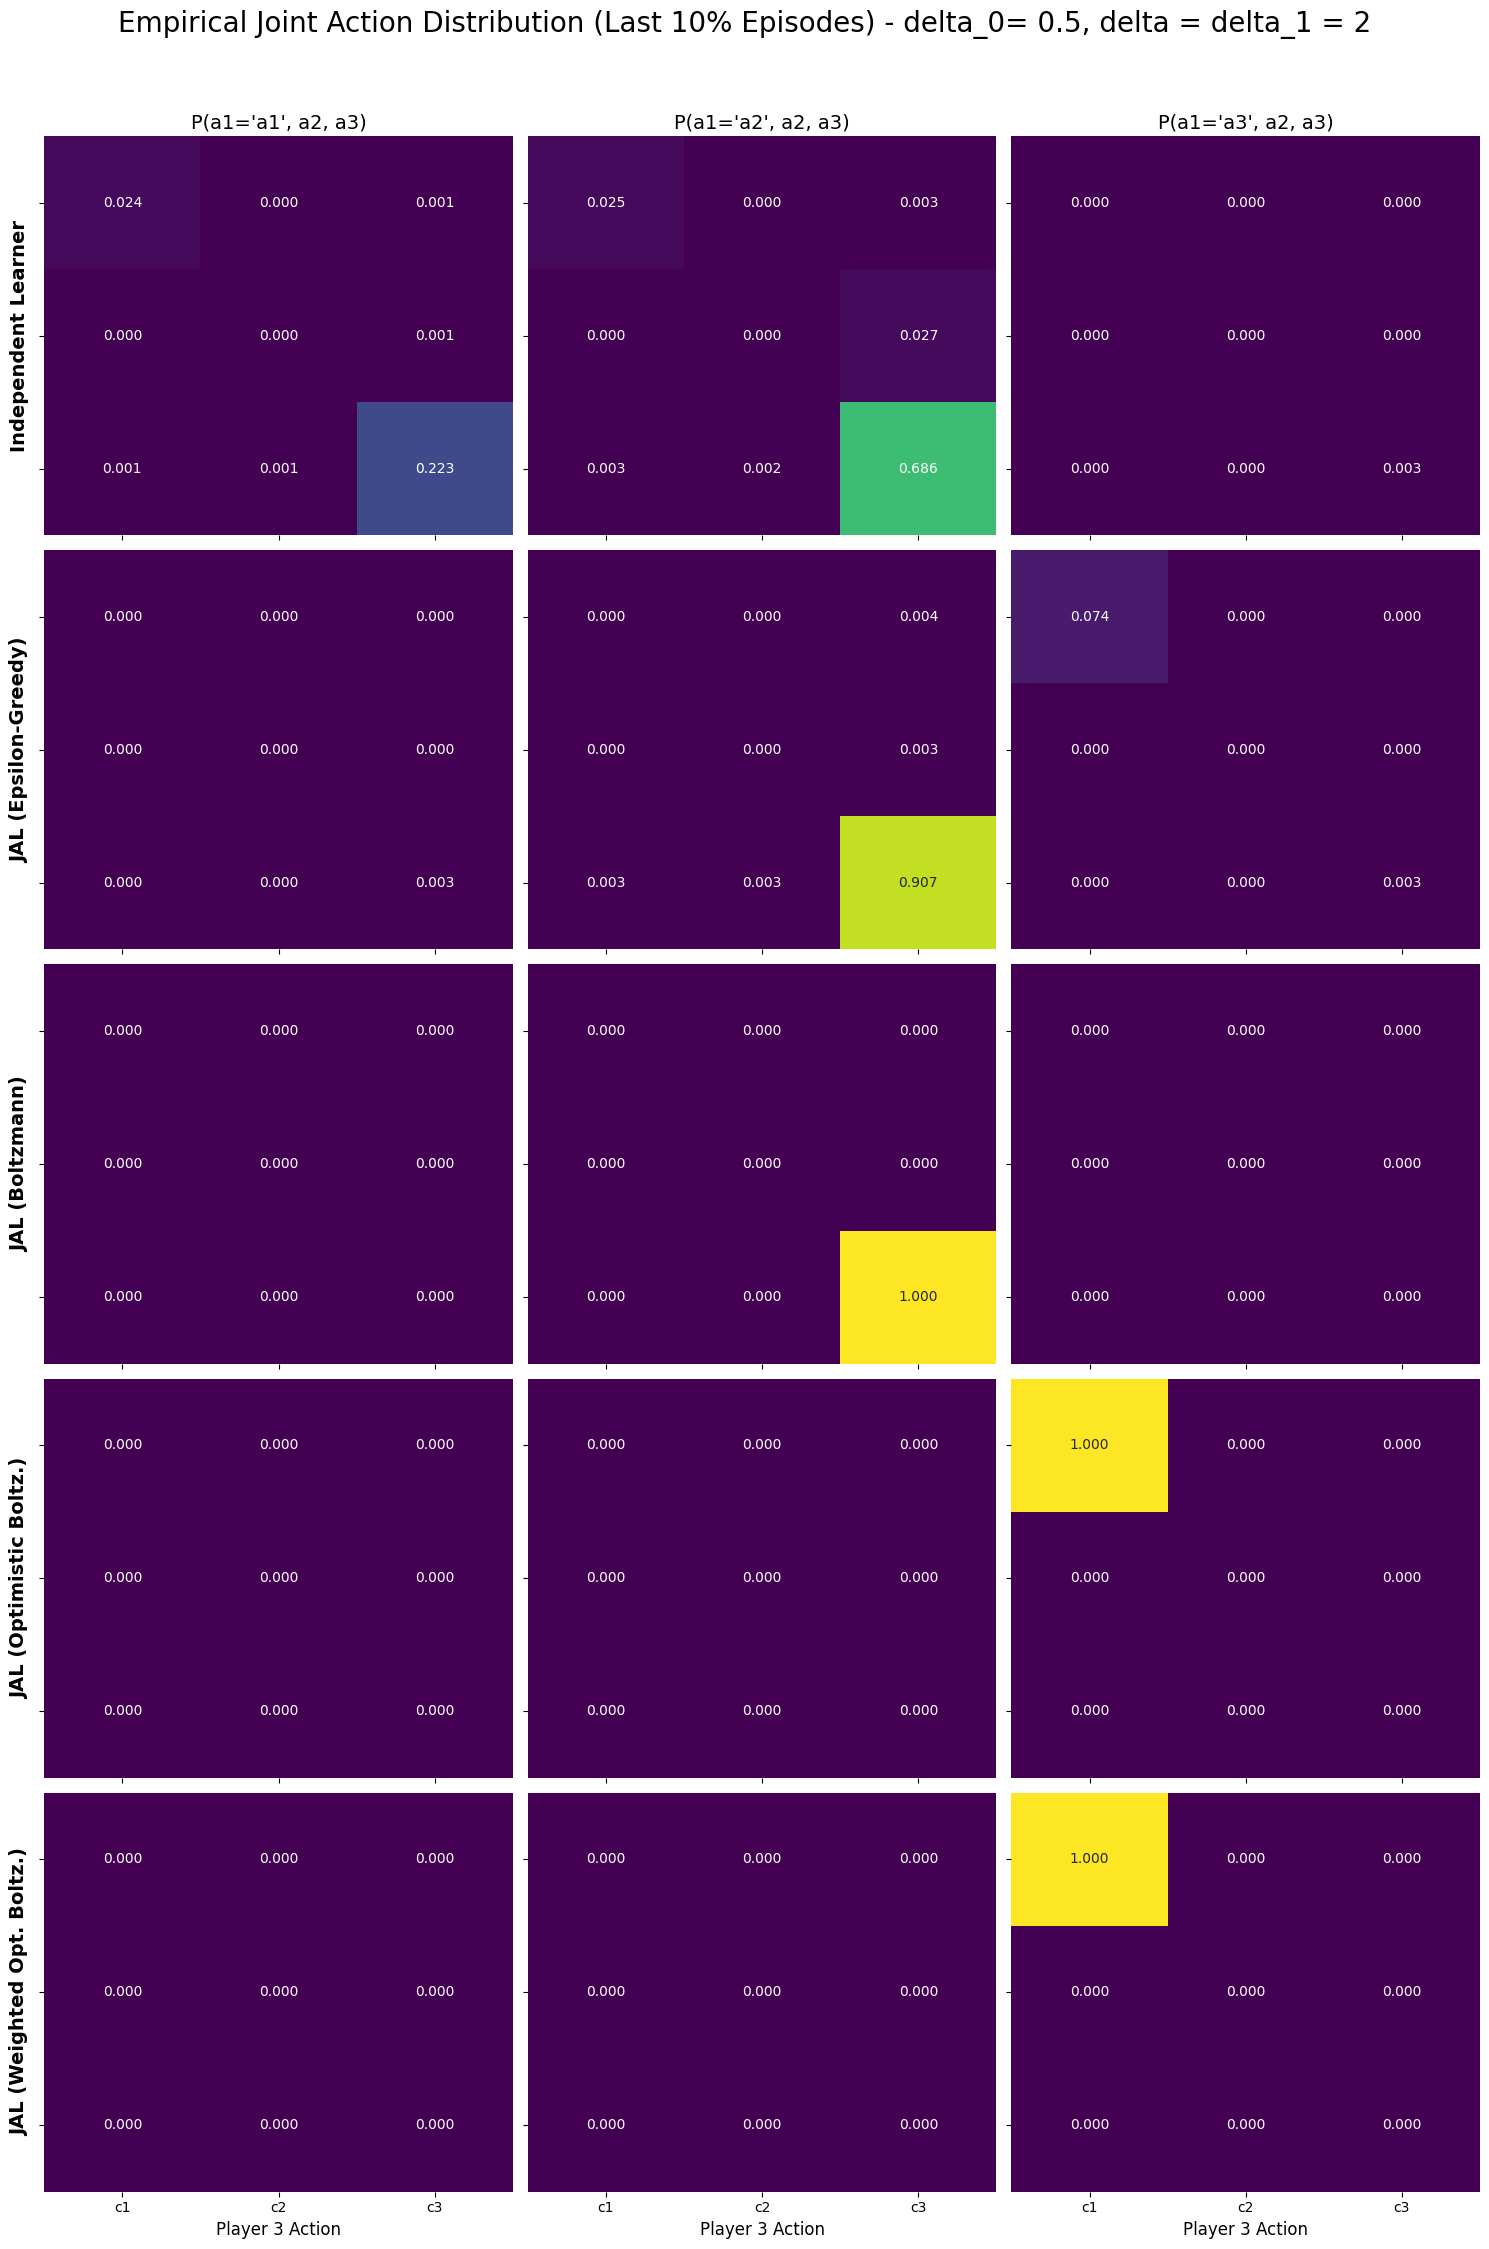

In [36]:
AGENT_TYPES = [
    "Independent Learner",
    "JAL (Epsilon-Greedy)",
    "JAL (Boltzmann)",
    "JAL (Optimistic Boltz.)",
    "JAL (Weighted Opt. Boltz.)"
]

plot_joint_action_heatmap(joint_action_counts, AGENT_TYPES, "delta_0= 0.5, delta = delta_1 = 2")